In [ ]:
# ================================================================
# ADAPTIVE LLM-BASED PARLIAMENTARY AGRICULTURE
# DEBATE INTELLIGENCE SYSTEM
#
# COMPLETE SINGLE-CELL GOOGLE COLAB CODE
#
# Includes:
# 1. Dataset upload and inspection
# 2. Text construction
# 3. Date/year/member standardization
# 4. Data cleaning
# 5. NLP preprocessing
# 6. Word frequency
# 7. TF-IDF
# 8. Agriculture entity extraction
# 9. Transformer NER
# 10. BERTopic
# 11. Topic labels
# 12. Sentence-BERT embeddings
# 13. Text chunking
# 14. FAISS semantic search
# 15. Adaptive Strategy Pattern
# 16. Question Strategy
# 17. Trend Strategy
# 18. Prediction Strategy
# 19. Improved RAG
# 20. FLAN-T5 LLM
# 21. Multiple RAG questions
# 22. Automatic evaluation
# 23. House analysis
# 24. Topic analysis
# 25. Yearly trend analysis
# 26. Future topic analysis
# 27. Visualizations
# 28. Excel result files
# 29. Final project summary
# ================================================================


# ================================================================
# 1. INSTALL PACKAGES
# ================================================================

!pip install -q nltk sentence-transformers faiss-cpu bertopic transformers accelerate openpyxl

print("=" * 70)
print("PACKAGES INSTALLED")
print("=" * 70)


# ================================================================
# 2. IMPORT LIBRARIES
# ================================================================

import os
import re
import time
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

import nltk

from google.colab import files

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.feature_extraction.text import TfidfVectorizer

from sentence_transformers import SentenceTransformer

import faiss

from bertopic import BERTopic

from transformers import (
    pipeline,
    AutoTokenizer,
    AutoModelForSeq2SeqLM
)

import torch


# ================================================================
# 3. DOWNLOAD NLTK RESOURCES
# ================================================================

print("\n" + "=" * 70)
print("DOWNLOADING NLTK RESOURCES")
print("=" * 70)

nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

print("NLTK ready!")


# ================================================================
# 4. UPLOAD DATASET
# ================================================================

print("\n" + "=" * 70)
print("UPLOAD DATASET")
print("=" * 70)

print("Upload your combined parliamentary agriculture Excel dataset.")

uploaded = files.upload()

if not uploaded:
    raise Exception("No dataset uploaded.")

file_name = list(uploaded.keys())[0]

print("\nUploaded file:", file_name)


# ================================================================
# 5. LOAD DATASET
# ================================================================

df = pd.read_excel(file_name)

print("\n" + "=" * 70)
print("DATASET LOADED")
print("=" * 70)

print("Dataset shape:", df.shape)

print("\nDataset columns:")
for i, col in enumerate(df.columns, start=1):
    print(i, ":", col)

print("\nFirst 5 records:")
display(df.head())


# ================================================================
# 6. DATASET INFORMATION
# ================================================================

print("\n" + "=" * 70)
print("DATASET INFORMATION")
print("=" * 70)

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())


# ================================================================
# 7. STANDARDIZE COLUMN NAMES
# ================================================================

df.columns = (
    df.columns
    .astype(str)
    .str.strip()
)

print("\nStandardized columns:")
print(df.columns.tolist())


# ================================================================
# 8. HOUSE COLUMN STANDARDIZATION
# ================================================================

if "House" not in df.columns:

    if "house" in df.columns:
        df["House"] = df["house"]

    else:
        df["House"] = "Unknown"

        # Try to infer from possible column names
        for col in df.columns:
            if col.lower() in ["loksabha", "rajyasabha"]:
                df["House"] = col

print("\nHouse distribution:")
print(df["House"].value_counts())


# ================================================================
# 9. CREATE UNIFIED TEXT
# ================================================================

print("\n" + "=" * 70)
print("CREATING UNIFIED PARLIAMENTARY TEXT")
print("=" * 70)

text_columns = [
    "debateTitle",
    "debateTypeDesc",
    "keywordUsed",
    "mpPartDetailList",
    "title",
    "debateTitleSubject",
    "type",
    "ministry",
    "content",
    "contents",
    "question",
    "answer",
    "debate",
    "speech",
    "description",
    "subject",
    "detail",
    "text"
]

# Keep only columns that actually exist
text_columns = [
    col for col in text_columns
    if col in df.columns
]

print("Text columns used:")
print(text_columns)


# ------------------------------------------------
# Create unified text
# ------------------------------------------------

if len(text_columns) > 0:

    df["text"] = (
        df[text_columns]
        .fillna("")
        .astype(str)
        .agg(" ".join, axis=1)
    )

else:
    raise Exception(
        "No suitable text/content columns were found in the dataset."
    )


# ------------------------------------------------
# Clean spaces
# ------------------------------------------------

df["text"] = (
    df["text"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print("\nUnified text created successfully.")

print("Text column sample:")
display(df[["House", "text"]].head())


# ================================================================
# 10. DATE STANDARDIZATION
# ================================================================

print("\n" + "=" * 70)
print("DATE STANDARDIZATION")
print("=" * 70)

if "debateDate" in df.columns and "date" in df.columns:

    df["unified_date"] = (
        df["debateDate"]
        .fillna(df["date"])
    )

elif "debateDate" in df.columns:

    df["unified_date"] = df["debateDate"]

elif "date" in df.columns:

    df["unified_date"] = df["date"]

else:

    df["unified_date"] = pd.NaT


df["unified_date"] = pd.to_datetime(
    df["unified_date"],
    errors="coerce"
)


# ================================================================
# 11. YEAR STANDARDIZATION
# ================================================================

if "year" in df.columns:

    df["unified_year"] = (
        df["unified_date"]
        .dt.year
    )

    df["unified_year"] = (
        df["unified_year"]
        .fillna(
            pd.to_numeric(
                df["year"],
                errors="coerce"
            )
        )
    )

else:

    df["unified_year"] = (
        df["unified_date"]
        .dt.year
    )


print("\nYear sample:")
display(
    df[
        ["House", "unified_date", "unified_year"]
    ].head(10)
)


# ================================================================
# 12. MEMBER STANDARDIZATION
# ================================================================

member_columns = [
    "memberName",
    "questionerName",
    "members"
]

available_member_columns = [
    col
    for col in member_columns
    if col in df.columns
]

if available_member_columns:

    df["unified_member"] = (
        df[available_member_columns]
        .bfill(axis=1)
        .iloc[:, 0]
    )

else:

    df["unified_member"] = "Unknown"


df["unified_member"] = (
    df["unified_member"]
    .fillna("Unknown")
    .astype(str)
)

print("\nMember sample:")
display(
    df[
        ["House", "unified_member"]
    ].head(10)
)


# ================================================================
# 13. REMOVE EMPTY TEXT
# ================================================================

print("\n" + "=" * 70)
print("REMOVING EMPTY TEXT")
print("=" * 70)

print("Before removing empty text:", df.shape)

df = df[
    df["text"].notna() &
    (df["text"].str.strip().str.len() > 0)
].copy()

df.reset_index(drop=True, inplace=True)

print("After removing empty text:", df.shape)


# ================================================================
# 14. REMOVE DUPLICATES
# ================================================================

before_duplicates = len(df)

df = df.drop_duplicates(
    subset=["House", "text"]
).reset_index(drop=True)

print(
    "Duplicates removed:",
    before_duplicates - len(df)
)

print(
    "Final records after duplicate removal:",
    len(df)
)


# ================================================================
# 15. CUSTOM STOPWORDS
# ================================================================

stop_words = set(
    stopwords.words("english")
)

custom_stopwords = {
    "question",
    "answer",
    "part",
    "written",
    "unstarred",
    "starred",
    "mpname",
    "mpcode",
    "mppartcode",
    "shri",
    "matter",
    "regarding",
    "affair"
}

stop_words.update(
    custom_stopwords
)

lemmatizer = WordNetLemmatizer()


# ================================================================
# 16. TEXT PREPROCESSING
# ================================================================

print("\n" + "=" * 70)
print("TEXT PREPROCESSING")
print("=" * 70)


def preprocess_text(text):

    text = str(text).lower()

    # Remove URLs
    text = re.sub(
        r"http\S+|www\S+",
        " ",
        text
    )

    # Remove HTML
    text = re.sub(
        r"<.*?>",
        " ",
        text
    )

    # Remove numbers
    text = re.sub(
        r"\d+",
        " ",
        text
    )

    # Keep alphabetic characters
    text = re.sub(
        r"[^a-zA-Z\s]",
        " ",
        text
    )

    # Remove extra spaces
    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    try:

        tokens = word_tokenize(text)

    except:

        tokens = text.split()

    tokens = [
        word
        for word in tokens
        if word not in stop_words
        and len(word) > 2
    ]

    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]

    return " ".join(tokens)


print("Preprocessing started...")

df["clean_text"] = (
    df["text"]
    .apply(preprocess_text)
)

df = df[
    df["clean_text"].str.len() > 0
].reset_index(drop=True)

print("Preprocessing completed!")

print("Dataset shape:", df.shape)

print("\nSample cleaned records:")
display(
    df[
        ["text", "clean_text"]
    ].head()
)


# ================================================================
# 17. PREPROCESSING QUALITY CHECK
# ================================================================

print("\n" + "=" * 70)
print("PREPROCESSING QUALITY CHECK")
print("=" * 70)

check_words = [
    "question",
    "answer",
    "affair",
    "matter",
    "regarding"
]

for word in check_words:

    count = df["clean_text"].str.contains(
        rf"\b{word}\b",
        case=False,
        regex=True
    ).sum()

    print(
        f"{word:15s} : {count} records"
    )


# ================================================================
# 18. WORD FREQUENCY
# ================================================================

print("\n" + "=" * 70)
print("WORD FREQUENCY")
print("=" * 70)

all_words = (
    " ".join(
        df["clean_text"]
    )
).split()

word_counts = Counter(
    all_words
)

print("\nTop 20 words:")

for word, count in word_counts.most_common(20):

    print(
        word,
        ":",
        count
    )


# ================================================================
# 19. TF-IDF
# ================================================================

print("\n" + "=" * 70)
print("TF-IDF")
print("=" * 70)

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2
)

X_tfidf = tfidf.fit_transform(
    df["clean_text"]
)

print(
    "TF-IDF shape:",
    X_tfidf.shape
)

feature_names = (
    tfidf.get_feature_names_out()
)

tfidf_scores = (
    X_tfidf.sum(axis=0).A1
)

top_tfidf = sorted(
    zip(
        feature_names,
        tfidf_scores
    ),
    key=lambda x: x[1],
    reverse=True
)

print("\nTop TF-IDF features:")

for word, score in top_tfidf[:20]:

    print(
        word,
        ":",
        round(score, 4)
    )


# ================================================================
# 20. AGRICULTURE ENTITY / KEYWORD EXTRACTION
# ================================================================

print("\n" + "=" * 70)
print("AGRICULTURE ENTITY EXTRACTION")
print("=" * 70)

agriculture_keywords = {

    "CROP": [
        "rice",
        "wheat",
        "turmeric",
        "cotton",
        "sugarcane",
        "maize",
        "millet",
        "pulses",
        "groundnut",
        "banana",
        "coconut",
        "tea",
        "coffee"
    ],

    "ISSUE": [
        "drought",
        "flood",
        "pest",
        "disease",
        "water shortage",
        "climate change",
        "farmer suicide"
    ],

    "POLICY": [
        "msp",
        "minimum support price",
        "pm kisan",
        "crop insurance",
        "subsidy",
        "agricultural loan"
    ],

    "RESOURCE": [
        "fertilizer",
        "irrigation",
        "water",
        "seed",
        "pesticide"
    ]
}


def extract_entities(text):

    text = str(text).lower()

    result = {}

    for category, keywords in agriculture_keywords.items():

        found = []

        for keyword in keywords:

            if keyword in text:
                found.append(keyword)

        result[category] = ", ".join(found)

    return result


entity_results = (
    df["text"]
    .apply(extract_entities)
)

for category in agriculture_keywords:

    df[
        category.lower()
    ] = entity_results.apply(
        lambda x: x[category]
    )

print(
    "Agriculture entities extracted."
)


# ================================================================
# 21. TRANSFORMER NER
# ================================================================

print("\n" + "=" * 70)
print("TRANSFORMER NAMED ENTITY RECOGNITION")
print("=" * 70)

print("Loading Transformer NER model...")

try:

    ner_pipeline = pipeline(
        "token-classification",
        model="dslim/bert-base-NER",
        aggregation_strategy="simple"
    )

    print("NER model loaded!")

    NER_SAMPLE_SIZE = min(
        100,
        len(df)
    )

    df["named_entities"] = ""

    print(
        f"Running NER on {NER_SAMPLE_SIZE} records..."
    )

    for idx in df.index[:NER_SAMPLE_SIZE]:

        try:

            text = str(
                df.loc[idx, "text"]
            )[:1000]

            entities = ner_pipeline(
                text
            )

            entity_text = ", ".join(
                [
                    f"{x['word']} ({x['entity_group']})"
                    for x in entities
                ]
            )

            df.loc[
                idx,
                "named_entities"
            ] = entity_text

        except Exception:
            df.loc[
                idx,
                "named_entities"
            ] = ""

    print("NER completed!")

except Exception as e:

    print(
        "NER could not be loaded:",
        e
    )

    df["named_entities"] = ""


# ================================================================
# 22. BERTopic
# ================================================================

print("\n" + "=" * 70)
print("BERTopic TOPIC MODELING")
print("=" * 70)

documents = (
    df["clean_text"]
    .tolist()
)

print(
    "Documents for BERTopic:",
    len(documents)
)

topic_model = BERTopic(
    language="english",
    min_topic_size=20,
    verbose=True
)

topics, probabilities = (
    topic_model.fit_transform(
        documents
    )
)

df["topic_id"] = topics

topic_info = (
    topic_model
    .get_topic_info()
)

print("\nDiscovered topics:")

display(
    topic_info.head(20)
)


# ================================================================
# 23. TOPIC LABELS
# ================================================================

print("\n" + "=" * 70)
print("CREATING TOPIC LABELS")
print("=" * 70)

topic_labels = {}

for topic_id in topic_info["Topic"]:

    if topic_id == -1:

        topic_labels[
            topic_id
        ] = "Other / Outlier"

        continue

    words = (
        topic_model
        .get_topic(topic_id)
    )

    if words:

        topic_labels[
            topic_id
        ] = " / ".join(
            [
                word
                for word, score
                in words[:5]
            ]
        )


df["topic_label"] = (
    df["topic_id"]
    .map(topic_labels)
    .fillna("Unknown")
)

print("\nTopic labels:")

for topic, label in list(
    topic_labels.items()
)[:20]:

    print(
        topic,
        "->",
        label
    )


# ================================================================
# 24. TEXT CHUNKING
# ================================================================

print("\n" + "=" * 70)
print("TEXT CHUNKING")
print("=" * 70)


def chunk_text(
    text,
    chunk_size=250,
    overlap=40
):

    words = str(text).split()

    if not words:
        return []

    chunks = []

    start = 0

    while start < len(words):

        end = start + chunk_size

        chunks.append(
            " ".join(
                words[start:end]
            )
        )

        if end >= len(words):
            break

        start += (
            chunk_size - overlap
        )

    return chunks


records = []

for idx, row in df.iterrows():

    chunks = chunk_text(
        row["text"]
    )

    for c in chunks:

        records.append({

            "chunk_text": c,

            "year": row[
                "unified_year"
            ],

            "house": row[
                "House"
            ],

            "source_row": idx,

            "topic_label": row[
                "topic_label"
            ]
        })


chunk_df = pd.DataFrame(
    records
)

print(
    f"Built {len(chunk_df)} chunks "
    f"from {len(df)} debate entries."
)


# ================================================================
# 25. SENTENCE-BERT EMBEDDINGS
# ================================================================

print("\n" + "=" * 70)
print("SENTENCE-BERT EMBEDDINGS")
print("=" * 70)

embed_model = SentenceTransformer(
    "all-MiniLM-L6-v2"
)

embeddings = embed_model.encode(
    chunk_df[
        "chunk_text"
    ].tolist(),

    batch_size=32,

    show_progress_bar=True,

    convert_to_numpy=True,

    normalize_embeddings=True
)

print(
    "Embedding shape:",
    embeddings.shape
)


# ================================================================
# 26. FAISS VECTOR DATABASE
# ================================================================

print("\n" + "=" * 70)
print("FAISS VECTOR DATABASE")
print("=" * 70)

embeddings = embeddings.astype(
    "float32"
)

dimension = (
    embeddings.shape[1]
)

faiss_index = faiss.IndexFlatIP(
    dimension
)

faiss_index.add(
    embeddings
)

print(
    "FAISS vectors:",
    faiss_index.ntotal
)

print(
    "Embedding dimension:",
    dimension
)


# ================================================================
# ================================================================
# 27. SEMANTIC RETRIEVAL
# ================================================================

print("\n" + "=" * 70)
print("SEMANTIC RETRIEVAL")
print("=" * 70)


def semantic_search(query, top_k=5):

    # Convert query into embedding
    query_embedding = embed_model.encode(
        [query],
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    # Make sure top_k does not exceed number of vectors
    top_k = min(
        top_k,
        faiss_index.ntotal
    )

    # Search FAISS
    scores, indices = faiss_index.search(
        query_embedding,
        top_k
    )

    results = []

    for score, index in zip(scores[0], indices[0]):

        if index < 0:
            continue

        result = chunk_df.iloc[index].copy()

        result["similarity_score"] = float(score)

        results.append(result)

    if len(results) == 0:
        return pd.DataFrame()

    return pd.DataFrame(results)


# ------------------------------------------------
# Test semantic search
# ------------------------------------------------

test_query = (
    "What are the major agricultural problems "
    "faced by farmers?"
)

search_results = semantic_search(
    test_query,
    top_k=5
)

print("\nQuery:")
print(test_query)

print("\nTop retrieved parliamentary records:")

if not search_results.empty:

    display(
        search_results[
            [
                "chunk_text",
                "year",
                "house",
                "topic_label",
                "similarity_score"
            ]
        ]
    )

else:

    print("No relevant results found.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 49.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.7/154.7 kB 7.7 MB/s eta 0:00:00
PACKAGES INSTALLED

DOWNLOADING NLTK RESOURCES
NLTK ready!

UPLOAD DATASET
Upload your combined parliamentary agriculture Excel dataset.


Saving Combined_Agriculture_LokSabha_RajyaSabha.xlsx to Combined_Agriculture_LokSabha_RajyaSabha.xlsx

Uploaded file: Combined_Agriculture_LokSabha_RajyaSabha.xlsx

DATASET LOADED
Dataset shape: (10800, 28)

Dataset columns:
1 : loksabha
2 : session
3 : dbSlno
4 : debateTitle
5 : memberName
6 : debateType
7 : debateTypeDesc
8 : debateDate
9 : keywordUsed
10 : mpPartDetailList
11 : House
12 : title
13 : debateTitleSubject
14 : date
15 : type
16 : sessionNo
17 : questionNo
18 : questionType
19 : resourceId
20 : year
21 : pageNoFromTo
22 : handle
23 : members
24 : questionerName
25 : ministerName
26 : language
27 : files
28 : ministry

First 5 records:


,loksabha,session,dbSlno,debateTitle,memberName,debateType,debateTypeDesc,debateDate,keywordUsed,mpPartDetailList,...,resourceId,year,pageNoFromTo,handle,members,questionerName,ministerName,language,files,ministry
0,18.0,1.0,60.0,Discussion on Motion of Thanks on the Presiden...,"['Shri Anurag Singh Thakur', 'Shri Om Birla', ...",26.0,MOTION OF THANKS ON THE PRESIDENT'S ADDRESS,01/07/2024,"['Farmers', 'Labour Laws', 'Medical Colleges',...","[{'mpName': 'Shri Anurag Singh Thakur', 'mpCod...",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,18.0,4.0,2631.0,"Union Budget (2025-2026)- Demands For Grants,...","['Shri Khagen Murmu', 'Smt. Poonamben Hematbha...",4.0,BUDGET (GENERAL),21/03/2025,"['Animal Husbandry', 'Cold Storage', 'Edible O...","[{'mpName': 'Shri Dharmendra Yadav', 'mpCode':...",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,18.0,3.0,1620.0,"The Disaster Management (Amendment) Bill, 2024...","['Shri Ram Shiromani Verma', 'Smt. Kanimozhi K...",14.0,GOVERNMENT BILLS,12/12/2024,"['Air Pollution', 'Compensation', 'Drought', '...","[{'mpName': 'Shri Ram Shiromani Verma', 'mpCod...",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,18.0,2.0,462.0,Combined discussion on General Budget; on the ...,"['Smt. Dimple Yadav', 'Shri Suresh Kumar Kashy...",4.0,BUDGET (GENERAL),29/07/2024,"['Agriculture', 'Armed Forces', 'Minority Grou...","[{'mpName': 'Smt. Dimple Yadav', 'mpCode': 458...",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,18.0,1.0,97.0,Motion of Thanks on the President`s Address (A...,"['Shri Vishnu Dayal Ram', 'Shri Devendra Singh...",26.0,MOTION OF THANKS ON THE PRESIDENT'S ADDRESS,02/07/2024,"['Agricultural Market', 'Arms Supply', 'Bullet...","[{'mpName': 'Shri Akhilesh Yadav', 'mpCode': 5...",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



DATASET INFORMATION

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 28 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   loksabha            2099 non-null   float64
 1   session             2099 non-null   float64
 2   dbSlno              2099 non-null   float64
 3   debateTitle         2099 non-null   object 
 4   memberName          2099 non-null   object 
 5   debateType          2099 non-null   float64
 6   debateTypeDesc      2099 non-null   object 
 7   debateDate          2099 non-null   object 
 8   keywordUsed         2099 non-null   object 
 9   mpPartDetailList    2099 non-null   object 
 10  House               10800 non-null  object 
 11  title               8701 non-null   object 
 12  debateTitleSubject  8700 non-null   object 
 13  date                8701 non-null   object 
 14  type                8701 non-null   object 
 15  sessionNo 

,House,text
0,Lok Sabha,Discussion on Motion of Thanks on the Presiden...
1,Lok Sabha,"Union Budget (2025-2026)- Demands For Grants, ..."
2,Lok Sabha,"The Disaster Management (Amendment) Bill, 2024..."
3,Lok Sabha,Combined discussion on General Budget; on the ...
4,Lok Sabha,Motion of Thanks on the President`s Address (A...


...


CREATING TOPIC LABELS

Topic labels:
-1 -> Other / Outlier
0 -> agriculture / growth / agricultural / horticulture / sector
1 -> processing / industry / food / fpis / pmksy
2 -> dairying / fishries / husbandry / animal / fishery
3 -> loan / finance / bank / waiver / credit
4 -> foodgrains / distribution / consumer / public / affair
5 -> drought / rain / flood / due / affected
6 -> irrigation / water / resource / shakti / project
7 -> bill / government / passing / consideration / withdrawal
8 -> petroleum / gas / natural / crude / price
9 -> fertilizer / chemical / unit / production / sector
10 -> fisherman / sri / lankan / indian / navy
11 -> pesticide / use / drone / banned / insecticide
12 -> remunerative / cost / production / produce / vegetable
13 -> university / welfare / farmer / implementation / pmfby
14 -> essential / rise / price / commodity / consumer
15 -> msp / rabi / crop / welfare / farmer
16 -> forest / environment / change / climate / tree
17 -> paddy / wheat / product

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/228 [00:00<?, ?it/s]

Embedding shape: (7276, 384)

FAISS VECTOR DATABASE
FAISS vectors: 7276
Embedding dimension: 384

SEMANTIC RETRIEVAL

Query:
What are the major agricultural problems faced by farmers?

Top retrieved parliamentary records:


,chunk_text,year,house,topic_label,similarity_score
3592,DISCUSSION ON THE VARIOUS PROBLEMS BEING FACED...,2015.0,Rajya Sabha,loan / finance / bank / waiver / credit,0.757003
1602,Need to resolve various problems being faced b...,2015.0,Rajya Sabha,Other / Outlier,0.751316
6999,REGARDING PROBLEMS BEING FACED BY THE FARMERS ...,2017.0,Rajya Sabha,Other / Outlier,0.743443
1011,Need to address the issues faced by Agricultur...,2024.0,Rajya Sabha,Other / Outlier,0.697404
7142,DEMAND FOR DISCUSSION ON THE PROBLEMS OF FARME...,2014.0,Rajya Sabha,Other / Outlier,0.692218



GENERATING VISUALIZATIONS

1. House-wise Parliamentary Record Distribution


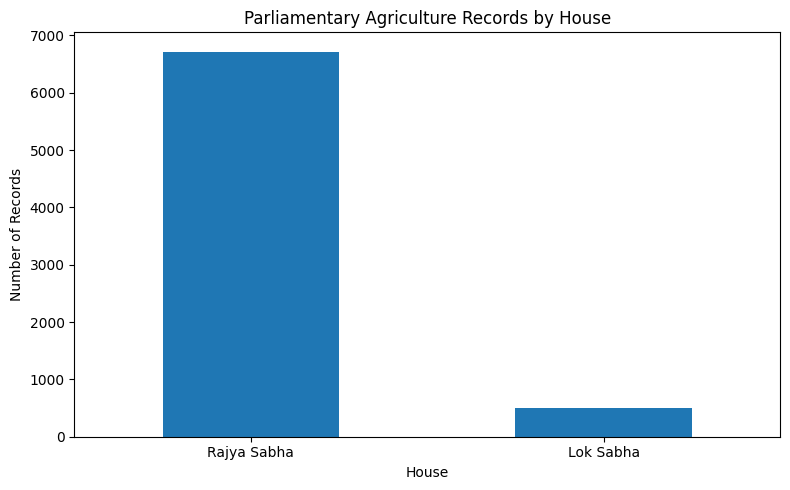


2. Year-wise Agriculture Parliamentary Records


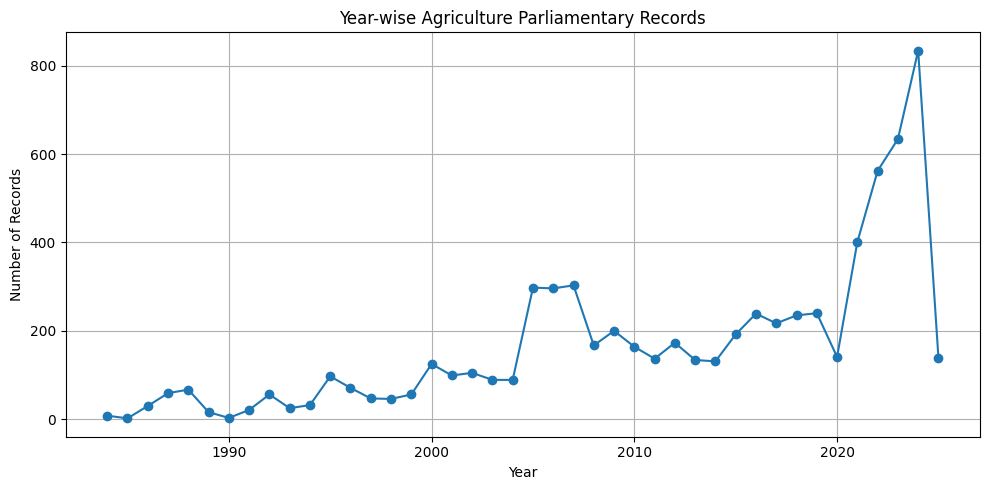


3. Top 20 Most Frequent Words


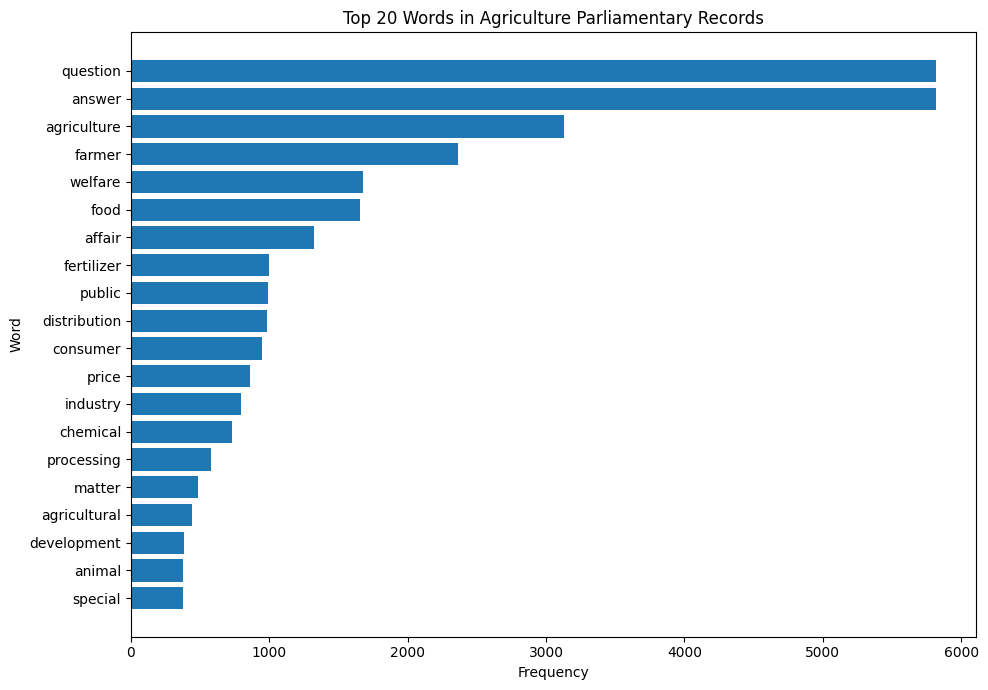


4. Top 20 TF-IDF Features


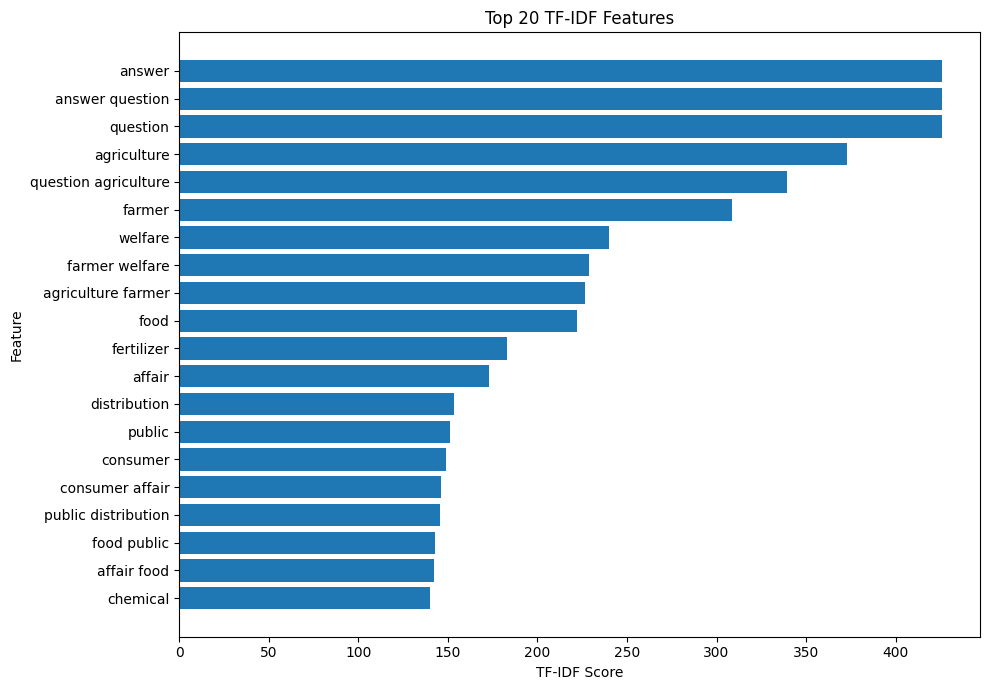


5. BERTopic Topic Distribution


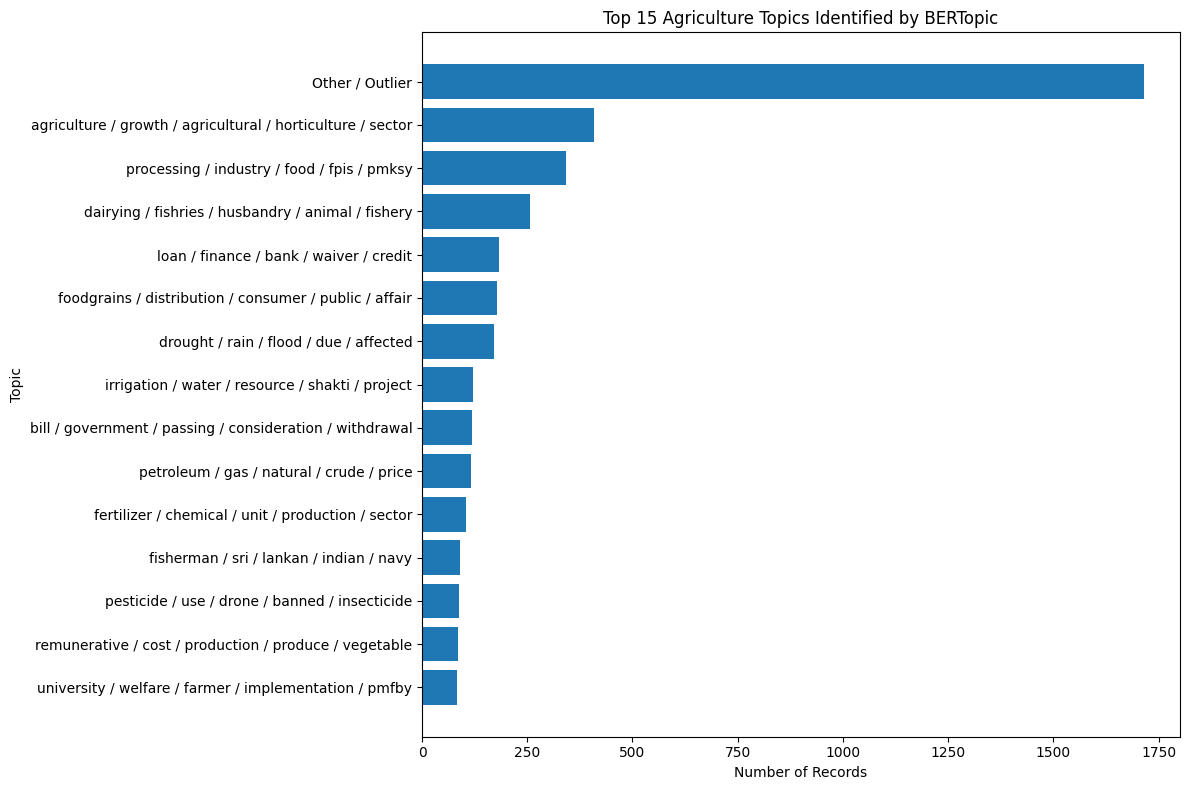


6. Agriculture Entity Category Distribution


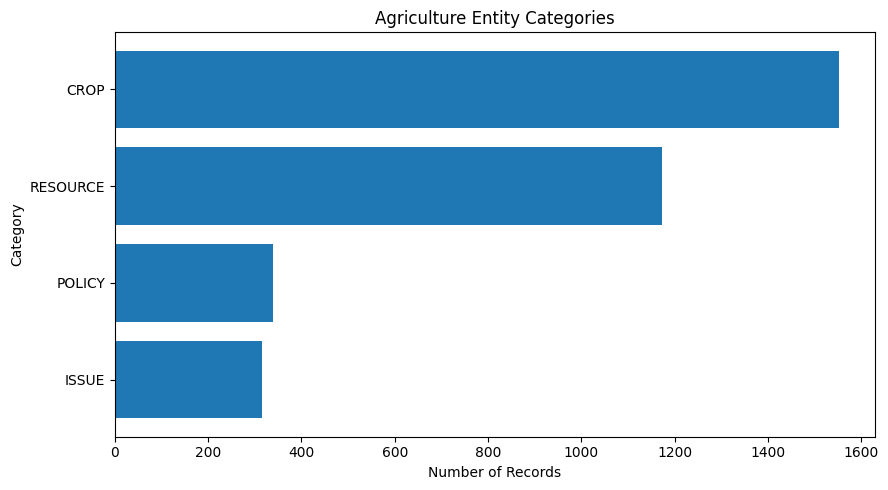


7. FAISS Semantic Retrieval Similarity


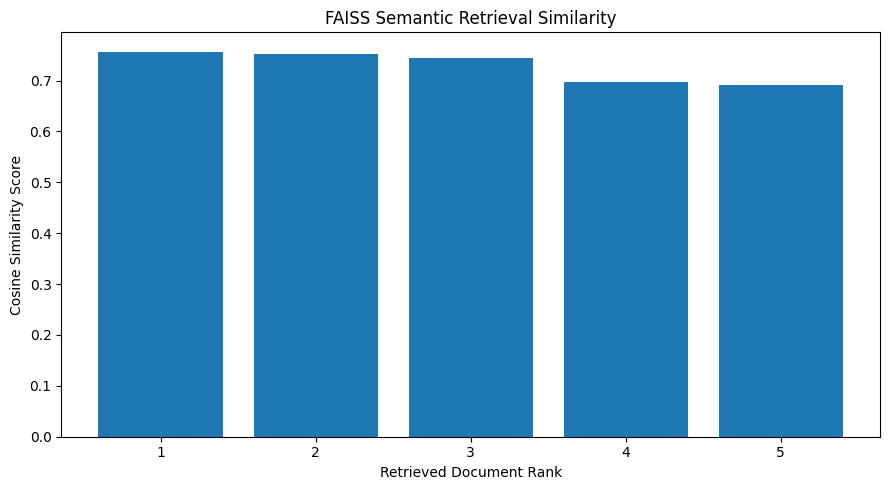


8. House-wise Yearly Agriculture Trend


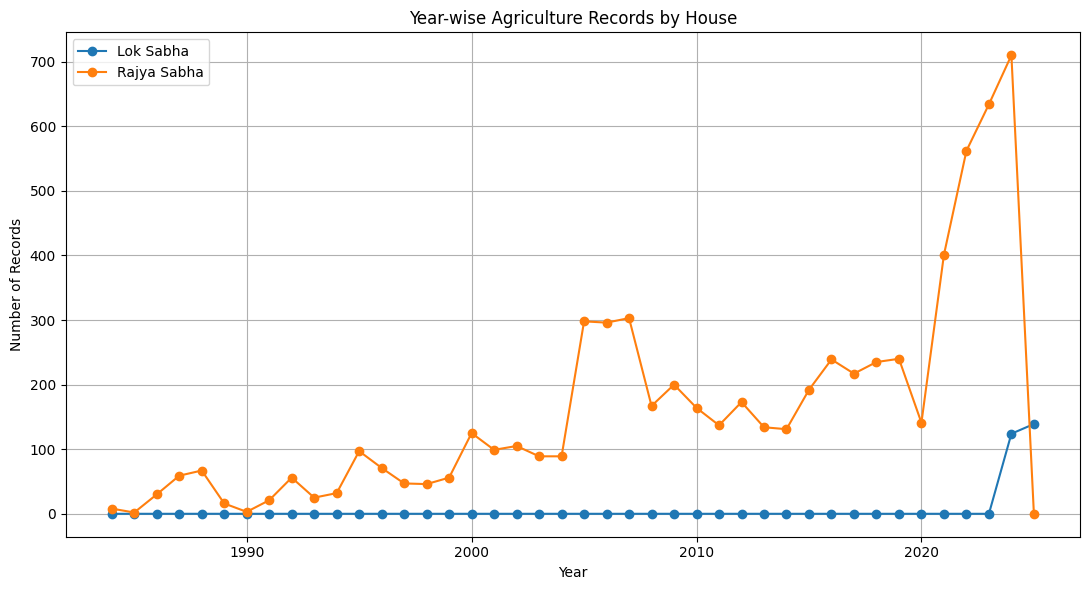


9. Topic Distribution by House


<Figure size 1200x800 with 0 Axes>

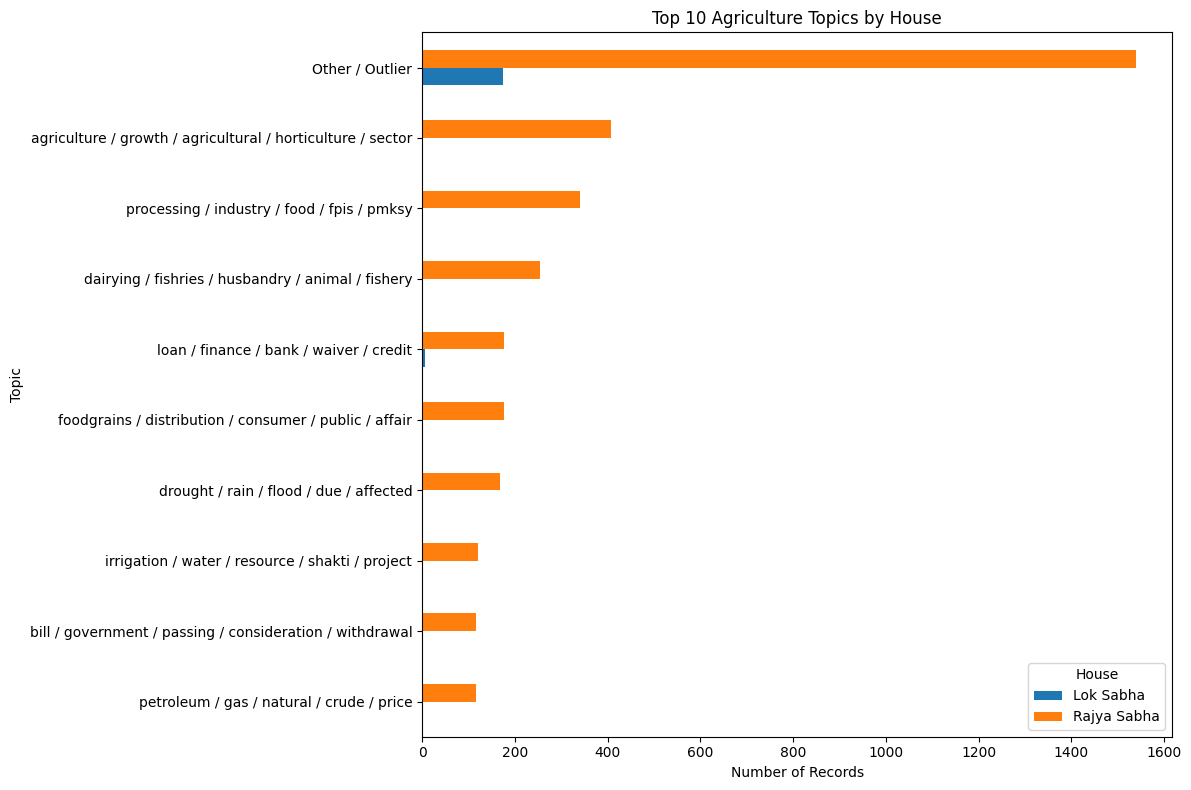


ALL VISUALIZATIONS GENERATED SUCCESSFULLY


In [ ]:
# ================================================================
# 28. VISUALIZATIONS
# ================================================================

print("\n" + "=" * 70)
print("GENERATING VISUALIZATIONS")
print("=" * 70)

# ================================================================
# GRAPH 1: HOUSE-WISE DISTRIBUTION
# ================================================================

print("\n1. House-wise Parliamentary Record Distribution")

house_counts = df["House"].value_counts()

plt.figure(figsize=(8, 5))
house_counts.plot(kind="bar")

plt.title("Parliamentary Agriculture Records by House")
plt.xlabel("House")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# ================================================================
# GRAPH 2: YEAR-WISE TREND
# ================================================================

print("\n2. Year-wise Agriculture Parliamentary Records")

year_counts = (
    df["unified_year"]
    .dropna()
    .astype(int)
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(10, 5))
plt.plot(
    year_counts.index,
    year_counts.values,
    marker="o"
)

plt.title("Year-wise Agriculture Parliamentary Records")
plt.xlabel("Year")
plt.ylabel("Number of Records")
plt.grid(True)
plt.tight_layout()
plt.show()


# ================================================================
# GRAPH 3: TOP 20 WORD FREQUENCY
# ================================================================

print("\n3. Top 20 Most Frequent Words")

top_words = word_counts.most_common(20)

words = [item[0] for item in top_words]
counts = [item[1] for item in top_words]

plt.figure(figsize=(10, 7))

plt.barh(
    words[::-1],
    counts[::-1]
)

plt.title("Top 20 Words in Agriculture Parliamentary Records")
plt.xlabel("Frequency")
plt.ylabel("Word")

plt.tight_layout()
plt.show()


# ================================================================
# GRAPH 4: TOP TF-IDF FEATURES
# ================================================================

print("\n4. Top 20 TF-IDF Features")

top_tfidf_graph = top_tfidf[:20]

tfidf_words = [
    item[0]
    for item in top_tfidf_graph
]

tfidf_values = [
    item[1]
    for item in top_tfidf_graph
]

plt.figure(figsize=(10, 7))

plt.barh(
    tfidf_words[::-1],
    tfidf_values[::-1]
)

plt.title("Top 20 TF-IDF Features")
plt.xlabel("TF-IDF Score")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


# ================================================================
# GRAPH 5: BERTopic TOPIC DISTRIBUTION
# ================================================================

print("\n5. BERTopic Topic Distribution")

topic_counts = (
    df["topic_label"]
    .value_counts()
    .head(15)
    .sort_values()
)

plt.figure(figsize=(12, 8))

plt.barh(
    topic_counts.index,
    topic_counts.values
)

plt.title("Top 15 Agriculture Topics Identified by BERTopic")
plt.xlabel("Number of Records")
plt.ylabel("Topic")

plt.tight_layout()
plt.show()


# ================================================================
# GRAPH 6: TOP AGRICULTURE CATEGORIES
# ================================================================

print("\n6. Agriculture Entity Category Distribution")

entity_category_counts = {}

for category in agriculture_keywords:

    column_name = category.lower()

    if column_name in df.columns:

        count = (
            df[column_name]
            .fillna("")
            .astype(str)
            .apply(lambda x: 1 if x.strip() else 0)
            .sum()
        )

        entity_category_counts[category] = count


if entity_category_counts:

    entity_series = pd.Series(
        entity_category_counts
    ).sort_values()

    plt.figure(figsize=(9, 5))

    plt.barh(
        entity_series.index,
        entity_series.values
    )

    plt.title("Agriculture Entity Categories")
    plt.xlabel("Number of Records")
    plt.ylabel("Category")

    plt.tight_layout()
    plt.show()


# ================================================================
# GRAPH 7: FAISS RETRIEVAL SIMILARITY
# ================================================================

print("\n7. FAISS Semantic Retrieval Similarity")

if not search_results.empty:

    retrieval_scores = (
        search_results["similarity_score"]
        .reset_index(drop=True)
    )

    ranks = range(
        1,
        len(retrieval_scores) + 1
    )

    plt.figure(figsize=(9, 5))

    plt.bar(
        ranks,
        retrieval_scores
    )

    plt.title(
        "FAISS Semantic Retrieval Similarity"
    )

    plt.xlabel("Retrieved Document Rank")
    plt.ylabel("Cosine Similarity Score")

    plt.xticks(
        list(ranks)
    )

    plt.tight_layout()
    plt.show()


# ================================================================
# GRAPH 8: HOUSE-WISE YEAR TREND
# ================================================================

print("\n8. House-wise Yearly Agriculture Trend")

house_year = (
    df.dropna(
        subset=["unified_year"]
    )
    .assign(
        unified_year=lambda x:
        x["unified_year"].astype(int)
    )
    .groupby(
        ["unified_year", "House"]
    )
    .size()
    .unstack(
        fill_value=0
    )
    .sort_index()
)

plt.figure(figsize=(11, 6))

for house in house_year.columns:

    plt.plot(
        house_year.index,
        house_year[house],
        marker="o",
        label=house
    )

plt.title(
    "Year-wise Agriculture Records by House"
)

plt.xlabel("Year")
plt.ylabel("Number of Records")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# ================================================================
# GRAPH 9: TOP 10 TOPICS BY HOUSE
# ================================================================

print("\n9. Topic Distribution by House")

top_topic_names = (
    df["topic_label"]
    .value_counts()
    .head(10)
    .index
)

topic_house = (
    df[
        df["topic_label"].isin(
            top_topic_names
        )
    ]
    .groupby(
        ["topic_label", "House"]
    )
    .size()
    .unstack(
        fill_value=0
    )
)

topic_house = topic_house.loc[
    topic_house.sum(axis=1).sort_values().index
]

plt.figure(figsize=(12, 8))

topic_house.plot(
    kind="barh",
    figsize=(12, 8)
)

plt.title(
    "Top 10 Agriculture Topics by House"
)

plt.xlabel("Number of Records")
plt.ylabel("Topic")

plt.tight_layout()
plt.show()


print("\n" + "=" * 70)
print("ALL VISUALIZATIONS GENERATED SUCCESSFULLY")
print("=" * 70)